In [11]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


pandas - для работы с таблицами и данными.
seaborn - более красивая надстройка над Matplotlib для визуализации данных
импортируем модель линейной регрессии
r2_score - (коэффициент детерминации) показывает, насколько хорошо модель объясняет данные.
mean_squared_error - среднеквадратичная ошибка
from sklearn.model_selection import train_test_split - берем функцию из готовой библиотеки, случайно разделяющая данные на train и test

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error as mse
from sklearn.model_selection import train_test_split

print("Все работает!")

Все работает!


df(data frame) - Таблица данных (строки + столбцы). через df получаем доступ к данным
print(df.head()) - по умолчанию показывает первые 5 строк
print(df.shape) - выводит размерность(сколько строк - обьектов и столбцов - признаков)
print(df.info()) - тип объекта, размер данных(индексы от 0, 4600 строк = 4600 примеров для обучения), колонки(18 признаков), пропуски, типы данных(float и int можно сразу использовать. Так как есть str - нужно преобразовать)

##  Данные
Смотрим на размер, типы и статистику. Обратите внимание на `price` в `describe()`: минимум 0 и максимум 26,59 млн при том, что 75% домов стоят до 655 тыс. Это выбросы и ошибки в данных.

df.describe() — это метод  Pandas, который выводит основную статистику по данным 

In [21]:
df_raw = pd.read_csv("data.csv")
print(df_raw.shape)
print("Домов с ценой 0:", (df_raw["price"] == 0).sum())
df_raw["price"].describe()

(4600, 18)
Домов с ценой 0: 49


count    4.600000e+03
mean     5.519630e+05
std      5.638347e+05
min      0.000000e+00
25%      3.228750e+05
50%      4.609435e+05
75%      6.549625e+05
max      2.659000e+07
Name: price, dtype: float64

Смотрим и выбираем что у нас будет Y(target) и X(features)

In [14]:
df.columns

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country', 'renovated'],
      dtype='str')

Target - price | 
X = df.drop("price", axis = 1) - означает, что берет все кроме столбца price и удаляет его полностью т.к. axis = 1

## Эксперимент 1, базовая модель

In [ ]:
y = df_raw["price"]
X = df_raw.drop(["price", "street", "city", "date", "statezip", "country"], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("R2 train:", r2_score(y_train, model.predict(X_train)))   
print("R2 test: ", r2_score(y_test, y_pred))                    
print("RMSE $:  ", np.sqrt(mse(y_test, y_pred)))               
print("MAE $:   ", mean_absolute_error(y_test, y_pred))       

R2 train: 0.5477017991963622
R2 test:  0.05963787830483003
RMSE $:   824236.9078228453
MAE $:    196135.02968580226


Чистка данных и новые признаки

In [ ]:
# убираем ошибки (цена 0) и верхний 1% цен; .copy() чтобы не было SettingWithCopyWarning
df = df_raw[df_raw["price"] > 0]
df = df[df["price"] < df["price"].quantile(0.99)].copy()
print("Осталось домов:", len(df))   

# yr_renovated: 0 значит "не ремонтировали", поэтому делаем признак 0/1
df["renovated"] = (df["yr_renovated"] > 0).astype(int)
df["age"] = 2014 - df["yr_built"]

num_features = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront",
                "view", "condition", "sqft_above", "sqft_basement", "age", "renovated"]

Осталось домов: 4505


## Эксперимент 2, без выбросов

In [28]:
y = df["price"]
X = df[num_features]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("R2 train:", r2_score(y_train, model.predict(X_train)))   # 0.561
print("R2 test: ", r2_score(y_test, y_pred))                    # 0.528
print("RMSE $:  ", np.sqrt(mse(y_test, y_pred)))                # 195 679
print("MAE $:   ", mean_absolute_error(y_test, y_pred))         # 142 081

R2 train: 0.5613280293913493
R2 test:  0.5283181548454108
RMSE $:   195678.63176788934
MAE $:    142081.15658813698


## Эксперимент 4, добавляем город

In [29]:
X = pd.get_dummies(df[num_features + ["city"]], columns=["city"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = LinearRegression()
model.fit(X_train, np.log1p(y_train))

pred_train = np.expm1(model.predict(X_train))
pred_test = np.expm1(model.predict(X_test))

print("R2 train:", r2_score(y_train, pred_train))   # 0.652
print("R2 test: ", r2_score(y_test, pred_test))     # 0.670
print("RMSE $:  ", np.sqrt(mse(y_test, pred_test))) # 163 701
print("MAE $:   ", mean_absolute_error(y_test, pred_test))  # 101 554

R2 train: 0.6650702347477615
R2 test:  0.6509495002776268
RMSE $:   168330.5547519037
MAE $:    102117.58614402312


## Эксперимент 5, почтовый индекс вместо города

In [30]:
X = pd.get_dummies(df[num_features + ["statezip"]], columns=["statezip"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = LinearRegression()
model.fit(X_train, np.log1p(y_train))

pred_train = np.expm1(model.predict(X_train))
pred_test = np.expm1(model.predict(X_test))

print("R2 train:", r2_score(y_train, pred_train))   # 0.763
print("R2 test: ", r2_score(y_test, pred_test))     # 0.762
print("RMSE $:  ", np.sqrt(mse(y_test, pred_test))) # 139 035
print("MAE $:   ", mean_absolute_error(y_test, pred_test))  # 86 379

R2 train: 0.7709413488464826
R2 test:  0.7707981722103673
RMSE $:   136404.23710356036
MAE $:    84301.18810315338


## График лучшей модели

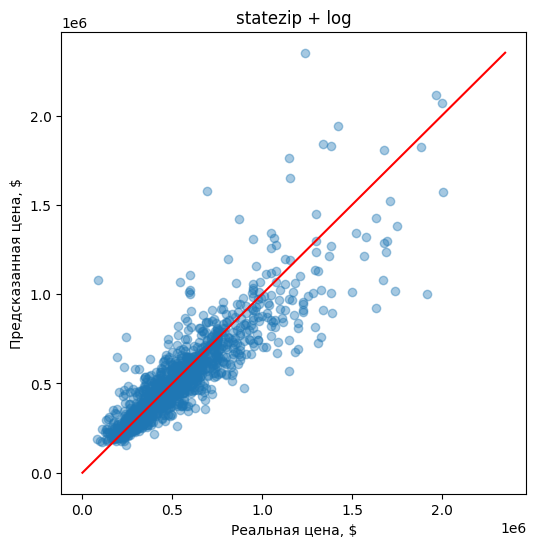

In [32]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test, alpha=0.4)
lim = [0, max(y_test.max(), pred_test.max())]
plt.plot(lim, lim, color="red")
plt.xlabel("Реальная цена, $")
plt.ylabel("Предсказанная цена, $")
plt.title("statezip + log")
plt.show()